# Практическое занятие №2: Градиентный спуск и оптимизаторы
**Цели занятия:**
- Научиться визуализировать функции потерь двух переменных (3D и линии уровня).
- Реализовать простой градиентный спуск (SGD) с помощью PyTorch и проследить траекторию оптимизации.
- Познакомиться с основными оптимизаторами из семейства gradient descent: SGD с моментом, RMSprop, Adam.
- Исследовать влияние скорости обучения (learning rate) на сходимость.

Слова "**Задание**" выделены жирным шрифтом по тексту.

## 1. Импорт необходимых библиотек
Установка и импорт:
- `torch` для автоматического дифференцирования и оптимизаторов.
- `numpy` для численных операций.
- `matplotlib` для построения графиков (3D, контурные, анимация).
- `ipywidgets` (опционально) для интерактивности.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation
from IPython.display import HTML
import warnings
warnings.filterwarnings('ignore')

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 2. Функции для визуализации
Определим две классические тестовые функции:
- **Функция Розенброка** (Rosenbrock) — «овражная» функция, сложная для оптимизации:
  $$f(x,y) = (a - x)^2 + b\,(y - x^2)^2,\quad a=1,\; b=100.$$
  Глобальный минимум в точке $(1,1)$.
- **Функция Химмельблау** (Himmelblau) — с несколькими локальными минимумами:
  $$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$
  Четыре локальных минимума: $(3,2)$, $(-2.805,3.131)$, $(-3.779,-3.283)$, $(3.584,-1.848)$.

In [2]:
def rosenbrock(x, y, a=1, b=100):
    return (a - x)**2 + b * (y - x**2)**2

def himmelblau(x, y):
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

# Создадим сетку для построения графиков
x = np.linspace(-2, 2, 100)
y = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x, y)
Z_rosen = rosenbrock(X, Y)

# Для Химмельблау возьмём более широкий диапазон
x_h = np.linspace(-5, 5, 100)
y_h = np.linspace(-5, 5, 100)
X_h, Y_h = np.meshgrid(x_h, y_h)
Z_himm = himmelblau(X_h, Y_h)

### 2.1 3D-визуализация функций
**Задание 1**: построить поверхности функций Розенброка и Химмельблау в 3D с возможностью интерактивного вращения. Обратите внимание на овраг у Розенброка и несколько впадин у Химмельблау.

Пример можно взять из лекции (библиотека plotly).

In [3]:
# Ваш ответ
import plotly.graph_objects as go

fig1 = go.Figure(data=[go.Surface(z=Z_rosen, x=X, y=Y)])
fig1.update_layout(title='Функция Розенброка', scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x, y)'))
fig1.show()

fig2 = go.Figure(data=[go.Surface(z=Z_himm, x=X_h, y=Y_h)])
fig2.update_layout(title='Функция Химмельблау', scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x, y)'))
fig2.show()

### 2.2 Контурные графики (линии уровня)
**Задание 2.** Нарисовать контурные графиках и точки глобальных (или локальных) минимумов на них.
Можно matplotlib или seaborn. (Проявить фантазию в оформлении!)

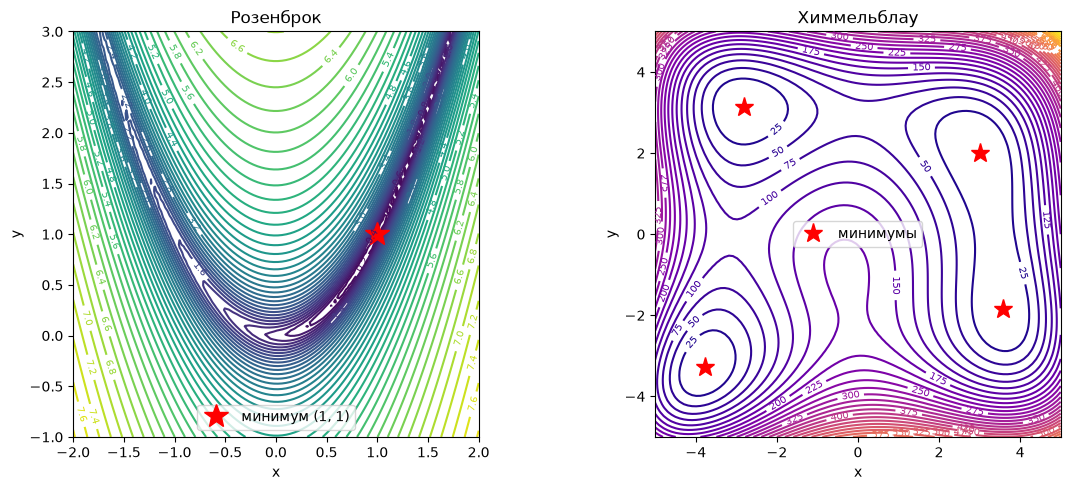

In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,5))

cs1 = axes[0].contour(X, Y, np.log1p(Z_rosen), levels=40, cmap='viridis')
axes[0].clabel(cs1, inline=True, fontsize=7)
axes[0].plot(1, 1, 'r*', markersize=18, label='минимум (1, 1)')
axes[0].set_title("Розенброк")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].legend(); axes[0].set_aspect('equal')

cs2 = axes[1].contour(X_h, Y_h, Z_himm, levels=40, cmap='plasma')
axes[1].clabel(cs2, inline=True, fontsize=7)
minima = [(3, 2), (-2.805, 3.131), (-3.779, -3.283), (3.584, -1.848)]
for i, (mx, my) in enumerate(minima):
    axes[1].plot(mx, my, 'r*', markersize=14,
                 label='минимумы' if i == 0 else None)
axes[1].set_title("Химмельблау")
axes[1].set_xlabel("x"); axes[1].set_ylabel("y")
axes[1].legend(); axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

**Задание 3.** Изучите полученные графики. Почему функция Розенброка считается сложной для градиентного спуска? (Ответьте в ячейке ниже)

*Ваш ответ:*  
1. Линии уровня образуют длинную долину, изогнутую вдоль параболы. Глобальный минимум находится на дне. Вдоль оврага фунция меняется медлена, а поперек - резко.
2. Траектория прыгает с одной стенки оврага на другую и почти не продвигается вперед. Точка долго колеблется поперек оврага и медленно идет к (1,1)

## 3. Реализация градиентного спуска (SGD) с помощью PyTorch

Будем минимизировать функцию двух переменных, используя автоматическое дифференцирование PyTorch. Создадим тензоры с включённым `requires_grad=True` и на каждом шаге будем обновлять их с помощью правила SGD:
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t).$$

В цикле оптимизации необходимо:
1. Вычислить значение функции.
2. Вызвать `.backward()` для вычисления градиентов.
3. Обновить параметры вручную (или с помощью оптимизатора).
4. Обнулить градиенты (`.grad.zero_()`).

Напишем функцию, которая выполняет заданное количество шагов SGD и записывает траекторию.

In [4]:
def sgd_trajectory(func, x0, y0, lr=0.01, steps=50):
    """
    Выполняет SGD для функции func(x,y) от двух переменных.
    Возвращает списки x_hist, y_hist, f_hist.
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        # Вычисляем функцию
        f = func(x, y)
        # Сохраняем историю (отсоединяем от графа вычислений)
        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

        # Градиенты
        f.backward()

        # Обновление вручную (SGD)
        with torch.no_grad():
            x -= lr * x.grad
            y -= lr * y.grad

        # Обнуляем градиенты
        x.grad.zero_()
        y.grad.zero_()

    return x_hist, y_hist, f_hist

Протестируем на функции Розенброка с начальной точкой (-1.5, 1.5), learning rate = 0.001 и 200 шагов. Построим траекторию на контурном графике.

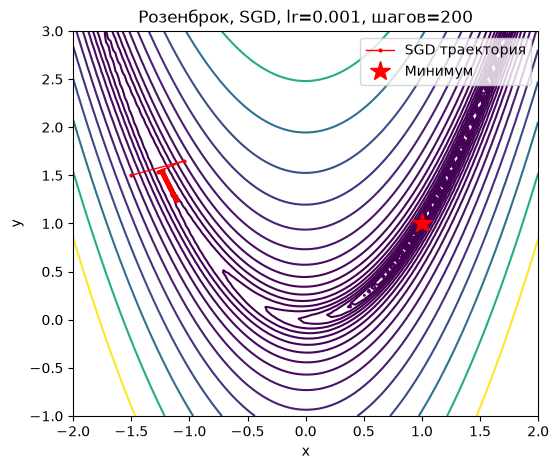

In [8]:
x0, y0 = -1.5, 1.5
lr = 0.001
steps = 200

x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, x0, y0, lr, steps)

# Визуализация
plt.figure(figsize=(6,5))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis')
plt.plot(x_hist, y_hist, 'r.-', markersize=4, linewidth=1, label='SGD траектория')
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Розенброк, SGD, lr={lr}, шагов={steps}')
plt.legend()
plt.show()

**Задание 4.** Поэкспериментируйте с learning rate и начальной точкой. Попробуйте для обеих функций:
- Попробовать 5 различных значений learning rate (например, 0.01, 0.05). Что происходит?
- Попробовать 5 различных начальных точек, например (0, 2) или (-1, -1) или случаным образом выбранных, надётся ли действительный глобальный минимум?

Результирующие графики всех экспериментов сохраните в отчётном блокноте.



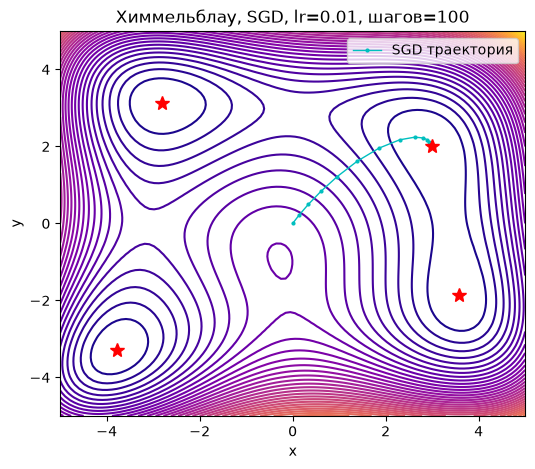

In [9]:
# Ваш эксперимент с Химмельблау
x0_h, y0_h = 0.0, 0.0
lr_h = 0.01
steps_h = 100

x_hist_h, y_hist_h, f_hist_h = sgd_trajectory(himmelblau, x0_h, y0_h, lr_h, steps_h)

plt.figure(figsize=(6,5))
plt.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma')
plt.plot(x_hist_h, y_hist_h, 'c.-', markersize=4, linewidth=1, label='SGD траектория')
# отметим минимумы
for mx, my in minima:
    plt.plot(mx, my, 'r*', markersize=10)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Химмельблау, SGD, lr={lr_h}, шагов={steps_h}')
plt.legend()
plt.show()

**Розенброк: 5 значений learning rate**

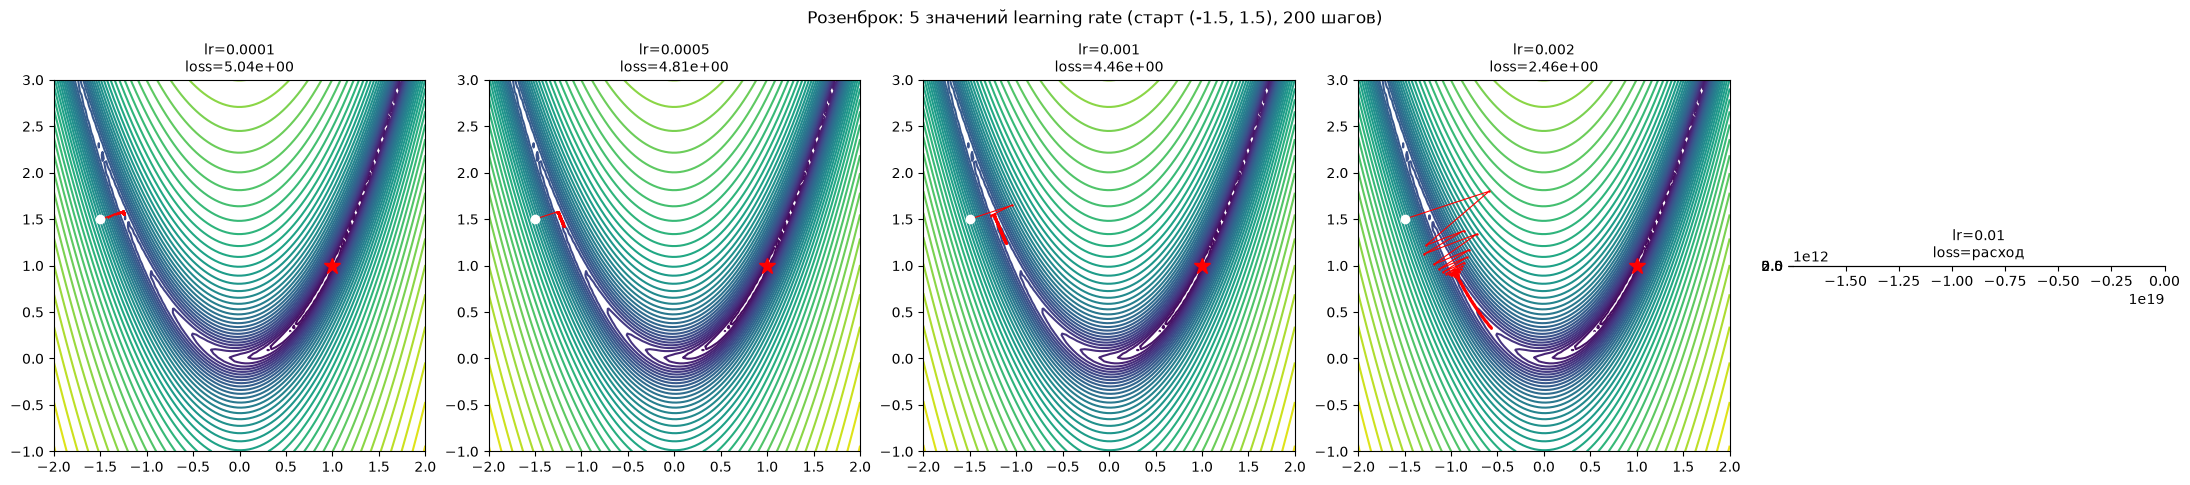

In [26]:
lrs = [0.0001, 0.0005, 0.001, 0.002, 0.01]
start = (-1.5, 1.5)
steps = 200

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, lr in zip(axes, lrs):
    x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, *start, lr=lr, steps=steps)
    ax.contour(X, Y, np.log1p(Z_rosen), levels=40, cmap='viridis')
    ax.plot(x_hist, y_hist, 'r.-', markersize=1.5, lw=0.8)
    ax.plot(*start, 'wo', ms=6)
    ax.plot(1, 1, 'r*', ms=12)
    diverge = (not np.isfinite(f_hist[-1])) or f_hist[-1] > 1e6 or abs(x_hist[-1]) > 10
    status = "расход" if diverge else f"{f_hist[-1]:.2e}"
    ax.set_title(f"lr={lr}\nloss={status}", fontsize=10)
    ax.set_aspect('equal')

plt.suptitle("Розенброк: 5 значений learning rate (старт (-1.5, 1.5), 200 шагов)", y=1.02)
plt.tight_layout()
plt.show()

Диапазон lr узкий, уже при lr=0.01 шаг становится больше ширины оврага, точка выбрасывается наружу и loss уходит в бесконечность

**Розенброк: 5 начальных точек**

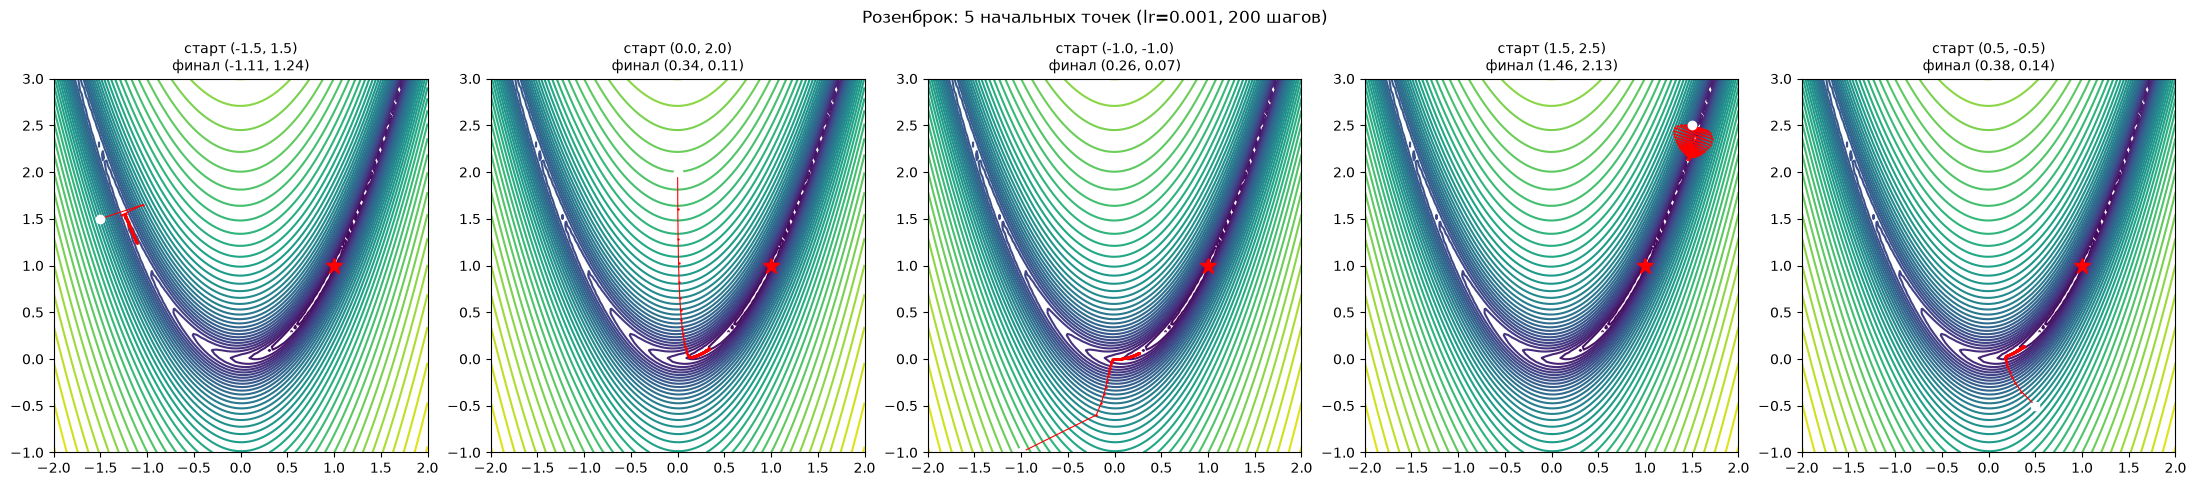

In [27]:
starts_r = [(-1.5, 1.5), (0.0, 2.0), (-1.0, -1.0), (1.5, 2.5), (0.5, -0.5)]
lr_r = 0.001
steps = 200

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, st in zip(axes, starts_r):
    x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, *st, lr=lr_r, steps=steps)
    ax.contour(X, Y, np.log1p(Z_rosen), levels=40, cmap='viridis')
    ax.plot(x_hist, y_hist, 'r.-', markersize=1.5, lw=0.8)
    ax.plot(*st, 'wo', ms=6, label='старт')
    ax.plot(1, 1, 'r*', ms=12, label='минимум')
    ax.set_title(f"старт {st}\nфинал ({x_hist[-1]:.2f}, {y_hist[-1]:.2f})", fontsize=10)
    ax.set_aspect('equal')

plt.suptitle("Розенброк: 5 начальных точек (lr=0.001, 200 шагов)", y=1.02)
plt.tight_layout()
plt.show()

Из любого старта траектория стремится к оврагу

**Химмельблау: 5 значений learning rate**

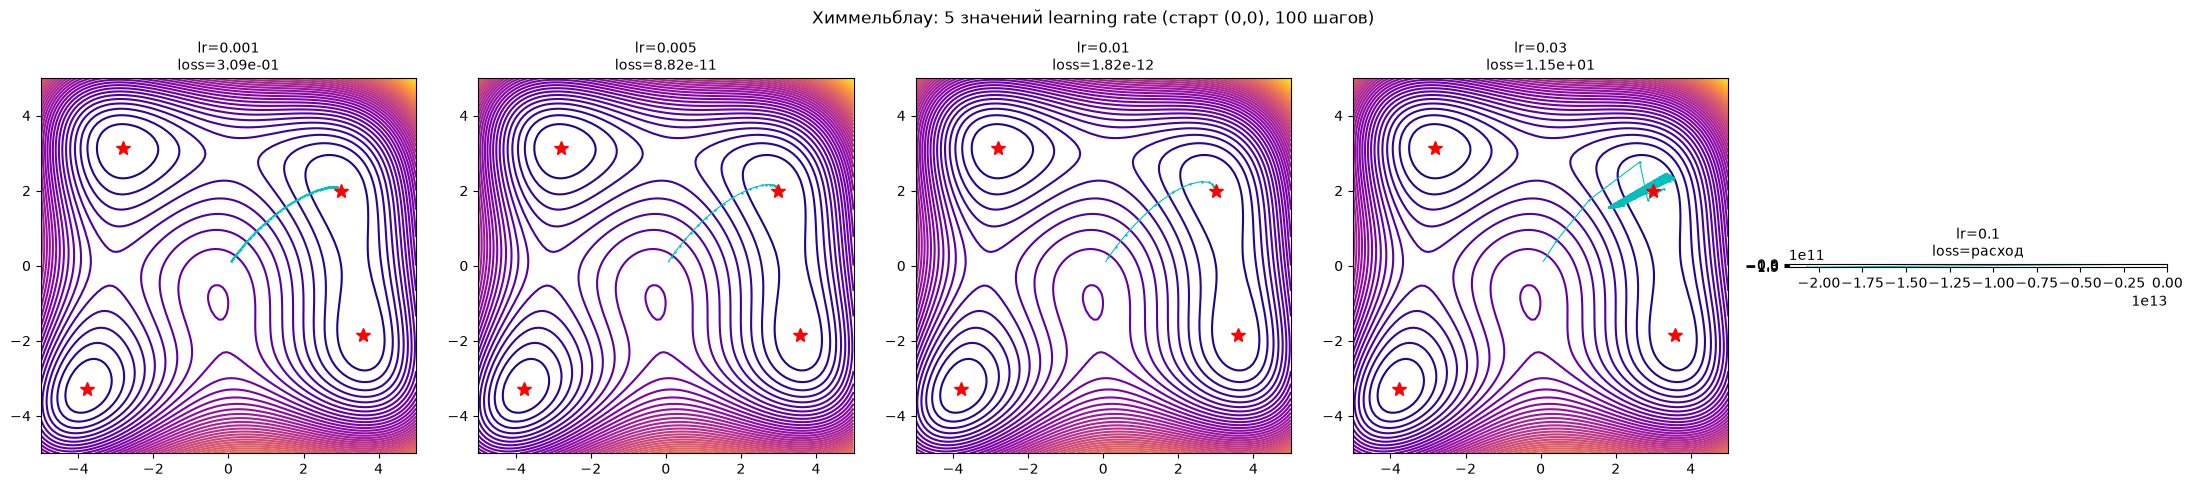

In [21]:
lrs_h = [0.001, 0.005, 0.01, 0.03, 0.1]
start_h = (0.0, 0.0)
steps_h = 100

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, lr in zip(axes, lrs_h):
    x_hist, y_hist, f_hist = sgd_trajectory(himmelblau, *start_h, lr=lr, steps=steps_h)
    ax.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma')
    ax.plot(x_hist, y_hist, 'c.-', markersize=1.5, lw=0.8)
    for mx, my in minima:
        ax.plot(mx, my, 'r*', ms=10)
    ax.plot(*start_h, 'wo', ms=6)
    diverge = (not np.isfinite(f_hist[-1])) or f_hist[-1] > 1e4
    status = "расход" if diverge else f"{f_hist[-1]:.2e}"
    ax.set_title(f"lr={lr}\nloss={status}", fontsize=10)
    ax.set_aspect('equal')

plt.suptitle("Химмельблау: 5 значений learning rate (старт (0,0), 100 шагов)", y=1.02)
plt.tight_layout()
plt.show() 

Оптимально lr = 0.005-0.01. При большом значении расходимость

**Химмельблау: 5 начальных точек**

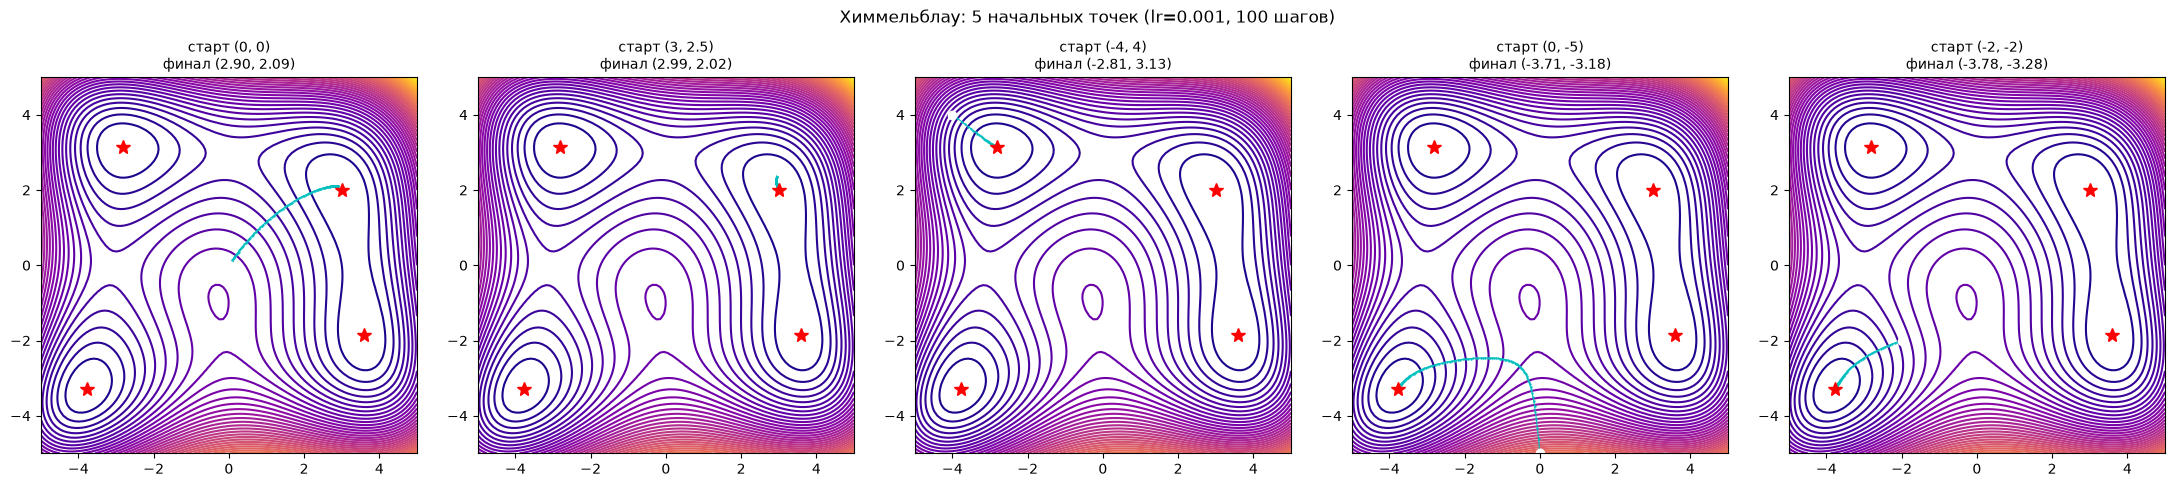

In [19]:
starts_h = [(0, 0), (3, 2.5), (-4, 4), (0, -5), (-2, -2)]
lr_h = 0.001
steps_h = 100

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, st in zip(axes, starts_h):
    x_hist, y_hist, f_hist = sgd_trajectory(himmelblau, *st, lr=lr_h, steps=steps_h)
    ax.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma')
    ax.plot(x_hist, y_hist, 'c.-', markersize=1.5, lw=0.8)
    ax.plot(*st, 'wo', ms=6, label='старт')
    for mx, my in minima:
        ax.plot(mx, my, 'r*', ms=10)
    ax.set_title(f"старт {st}\nфинал ({x_hist[-1]:.2f}, {y_hist[-1]:.2f})", fontsize=10)
    ax.set_aspect('equal')

plt.suptitle("Химмельблау: 5 начальных точек (lr=0.001, 100 шагов)", y=1.02)
plt.tight_layout(); plt.show()

Старт из верзней половины уходит в верхние минимумы, из нижней - в нижние

## 4. Сравнение оптимизаторов из torch.optim

PyTorch предоставляет готовые реализации многих оптимизаторов: SGD (с momentum и nesterov), RMSprop, Adam и др. Мы можем использовать их, передав параметры модели. В нашем случае модель — это просто два тензора x и y.

Напишем функцию, которая принимает оптимизатор (например, `torch.optim.SGD`), его параметры и возвращает траекторию.

In [28]:
def optimizer_trajectory(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

### 4.1 Сравнение на функции Розенброка
Возьмём начальную точку (-1.5, 1.5), 100 шагов, и сравним:
- SGD (learning rate = 0.001)
- SGD с моментом (lr=0.001, momentum=0.9)
- RMSprop (lr=0.01)
- Adam (lr=0.01)

Построим все траектории на одном контурном графике.

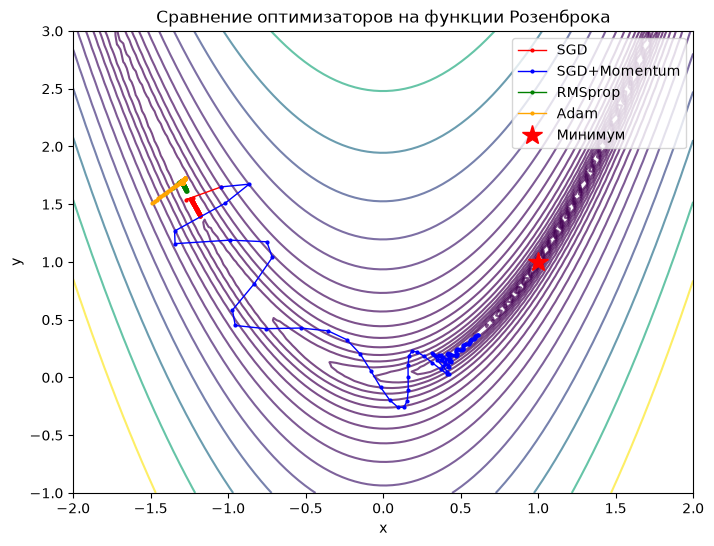

In [29]:
x0, y0 = -1.5, 1.5
steps = 100

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

**Задание 5. Вопросы для анализа:**
- Какой оптимизатор быстрее достиг окрестности минимума?

    SGD + Momentum продвинулся дальше всех и ближе всех подобрался к минимуму
    
- Как ведёт себя SGD без момента? Почему он "застревает" в овраге?

    SGD без момента прошел очень короткий путь, шаг lr=0.001 очень мал для движения вдоль оврага. Точка застревает

- Почему Adam и RMSprop работают лучше?

    Они тоже продвигаются не быстро. Возможно дело в параметрах или недостаточное количество итераций
    
- Сравнить оптимизаторы по итоговому найденному значению минимизируемой функции.

    SGD + Momentum - самое нихкое значение функции, SGD - худший

- Сравнить времена работы (эффективность/производительность) оптимизаторов. Если на одинаковом количестве итераций они оказались примерно одинаковые, попробовать увеличить количество итераций так, чтобы 1-2 метода успели попасть в небольшую окрестность глобального минимума и сравнить методы по количеству этих итераций.

    За одинаковое количество итераций SGD + Momentum продемонстрировал лучшую эффективность и прошел большую дистанцию. Другим методам не хватает количество итераций, оптимального значения lr

In [30]:
def optimizer_trajectory_1(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)
    eps = 0.05
    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        if abs(x.item()-1)<eps and abs(y.item()-1)<eps:
            print("Количество итераций: "+str(i+1))
            break

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

Количество итераций: 623


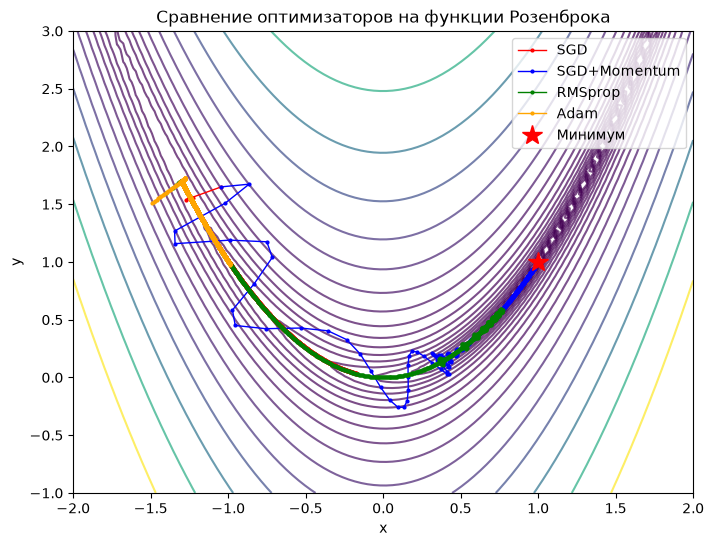

In [33]:
x0, y0 = -1.5, 1.5
steps = 1000

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory_1(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

### 4.2 Анимация траекторий (дополнительно)
Для наглядности можно создать анимацию движения точек. Ниже приведён код для создания GIF-анимации с помощью matplotlib.animation. Запустите эту ячейку, чтобы увидеть, как оптимизаторы "шагают" к минимуму.

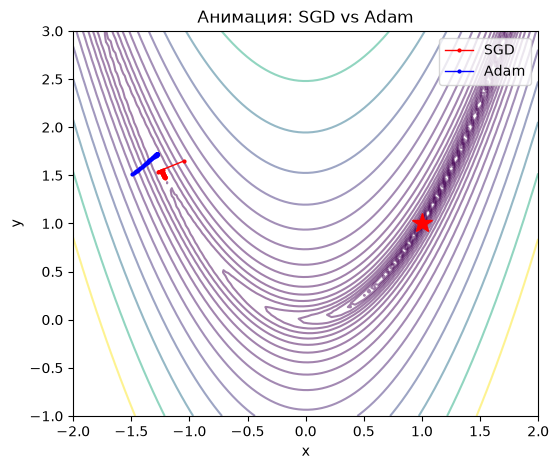

In [35]:
# Создаём анимацию для двух оптимизаторов: SGD и Adam
fig, ax = plt.subplots(figsize=(6,5))
ax.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
ax.plot(1, 1, 'r*', markersize=15)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Анимация: SGD vs Adam')

line_sgd, = ax.plot([], [], 'r.-', lw=1, markersize=4, label='SGD')
line_adam, = ax.plot([], [], 'b.-', lw=1, markersize=4, label='Adam')
ax.legend()

# Получаем траектории (первые steps точек)
steps_anim = 50  # возьмём первые 50 шагов для анимации
x_sgd, y_sgd = trajectories['SGD'][0][:steps_anim], trajectories['SGD'][1][:steps_anim]
x_adam, y_adam = trajectories['Adam'][0][:steps_anim], trajectories['Adam'][1][:steps_anim]

def init():
    line_sgd.set_data([], [])
    line_adam.set_data([], [])
    return line_sgd, line_adam

def animate(i):
    line_sgd.set_data(x_sgd[:i+1], y_sgd[:i+1])
    line_adam.set_data(x_adam[:i+1], y_adam[:i+1])
    return line_sgd, line_adam

anim = animation.FuncAnimation(fig, animate, init_func=init, frames=steps_anim, interval=100, blit=True)

# Для отображения в блокноте:
#HTML(anim.to_html5_video())
anim.save('comparison.gif', writer='pillow')
# Если не работает, можно сохранить в gif: anim.save('comparison.gif', writer='pillow')

## 5. Влияние скорости обучения (learning rate) на сходимость

Проведём эксперимент: зафиксируем начальную точку (-1.5, 1.5) и оптимизатор SGD (без момента). Будем менять learning rate: очень маленький (0.0001), средний (0.001), большой (0.01) и слишком большой (0.1). Наблюдаем поведение.

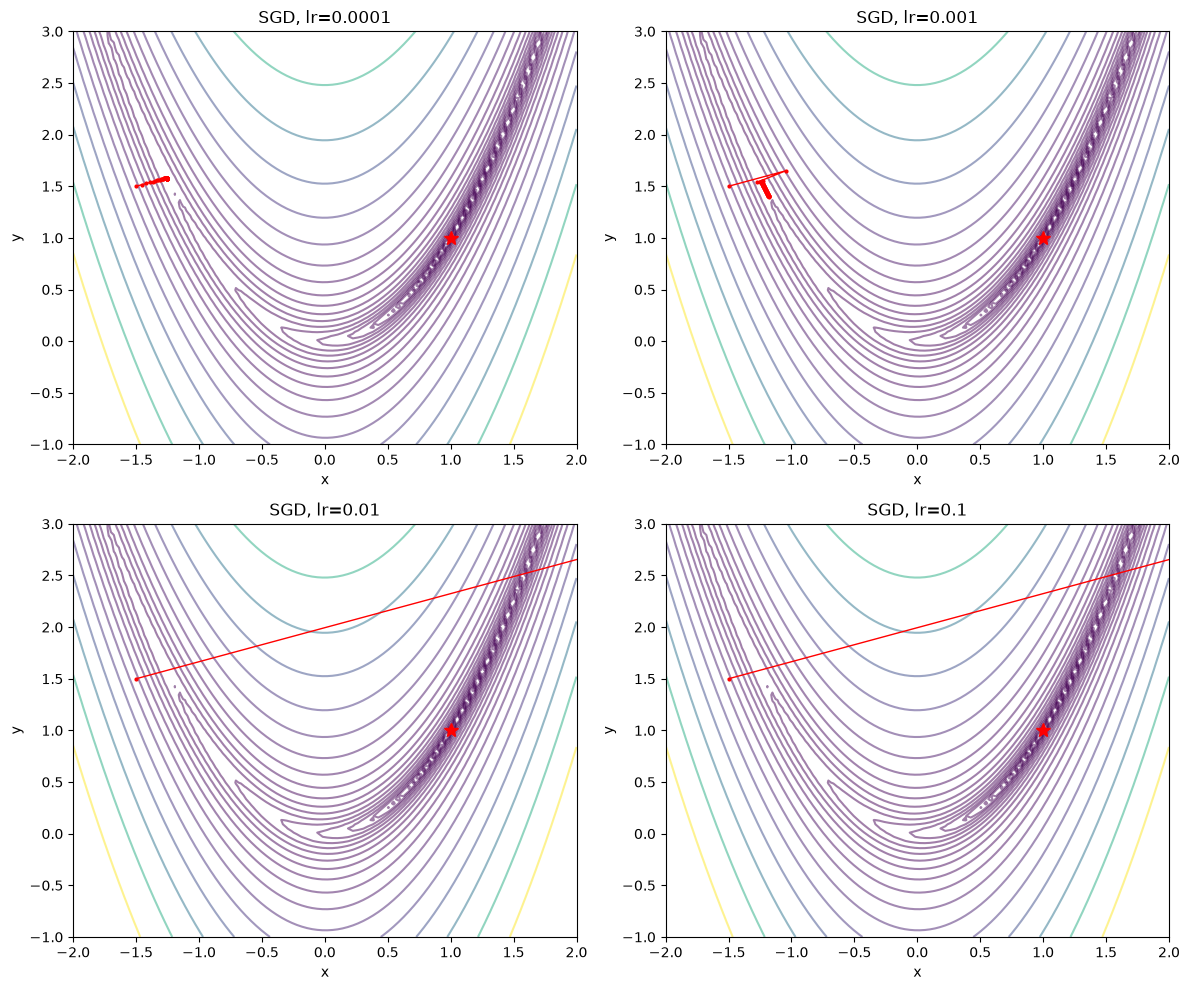

In [36]:
lrs_to_try = [0.0001, 0.001, 0.01, 0.1]
x0, y0 = -1.5, 1.5
steps = 100

plt.figure(figsize=(12,10))

for i, lr in enumerate(lrs_to_try):
    xh, yh, fh = sgd_trajectory(rosenbrock, x0, y0, lr, steps)
    plt.subplot(2,2,i+1)
    plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
    plt.plot(xh, yh, 'r.-', markersize=4, linewidth=1)
    plt.plot(1, 1, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'SGD, lr={lr}')
    plt.xlim(-2,2)
    plt.ylim(-1,3)

plt.tight_layout()
plt.show()

**Обсуждение:**
- При очень маленьком LR (0.0001) алгоритм не успевает дойти до минимума за 100 шагов.
- При LR=0.001 траектория медленно сползает в овраг и движется к минимуму.
- При LR=0.01 шаги больше, но из-за оврага траектория может "перепрыгивать" и колебаться.
- При LR=0.1 градиентный спуск расходится: шаги становятся настолько большими, что точка улетает за пределы графика. Это иллюстрация "взрыва градиентов" (хотя здесь не градиенты взрываются, а слишком большой шаг).

**Задание 6.** Для функции Химмельблау и начальной точки (0, 0) подберите такое значение learning rate для SGD, чтобы алгоритм сошёлся к одному из минимумов, но при этом траектория была "интересной" (например, с колебаниями). Попробуйте также очень большое LR и посмотрите, куда улетает точка.

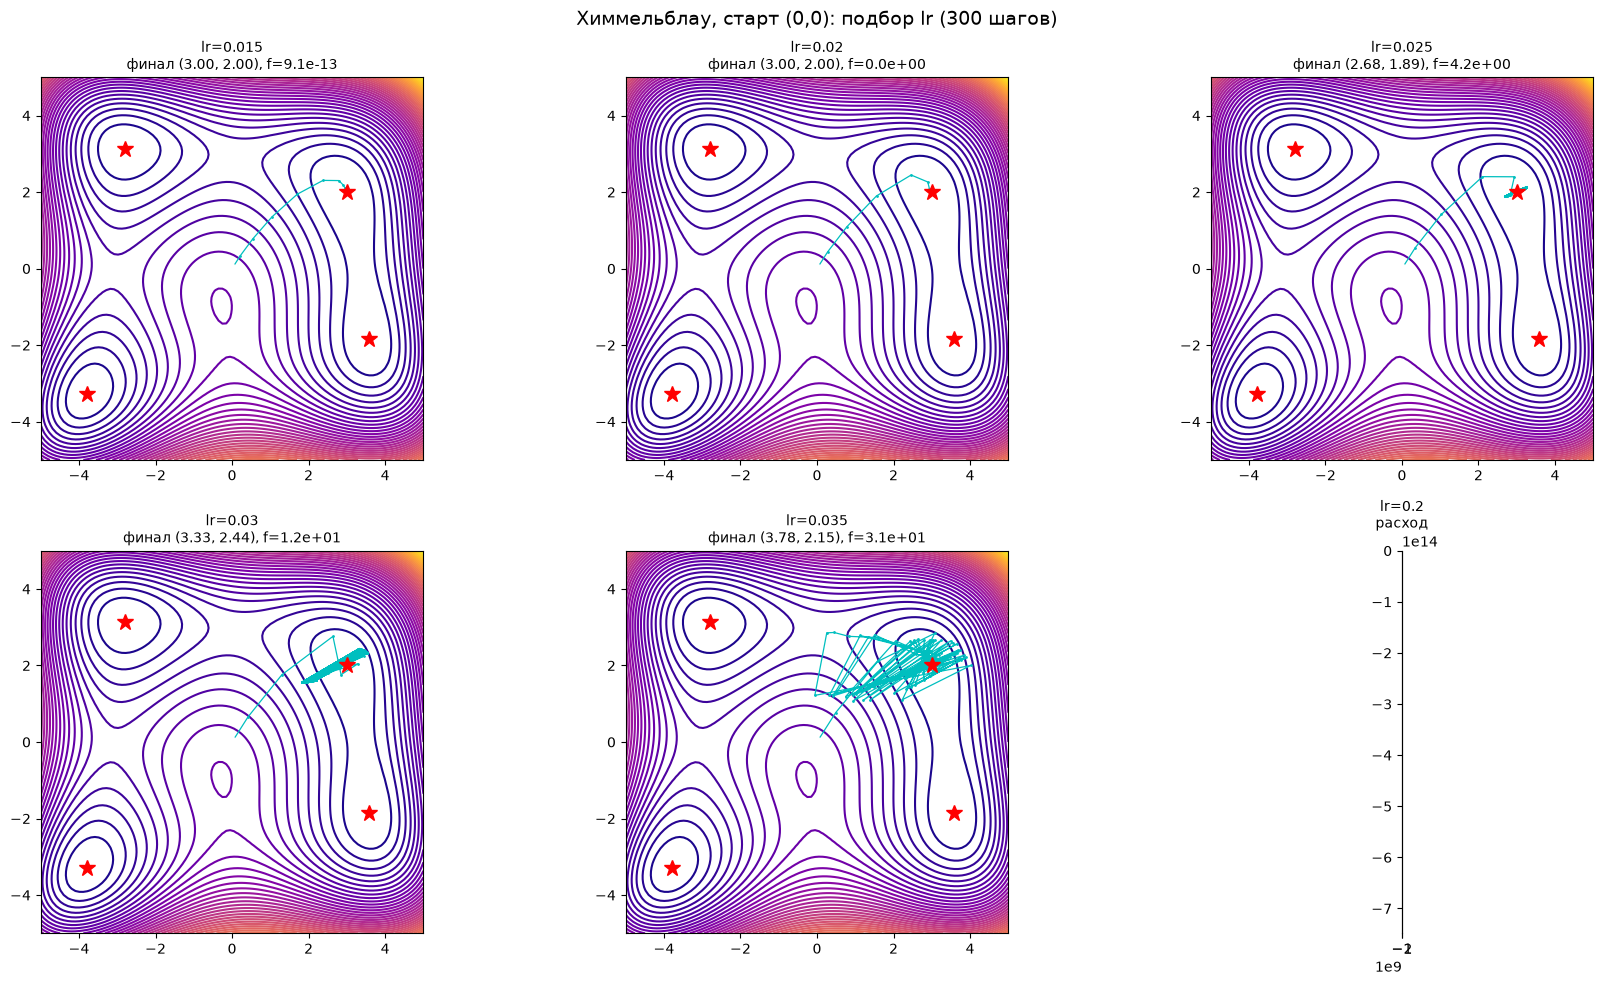

In [43]:
# Ваш эксперимент с Химмельблау и разными LR
lrs = [0.015, 0.02, 0.025, 0.03, 0.035, 0.2]
start = (0.0, 0.0)
steps = 100

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, lr in zip(axes, lrs):
    xh, yh, fh = sgd_trajectory(himmelblau, *start, lr=lr, steps=steps)
    ax.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma')
    ax.plot(xh, yh, 'c.-', markersize=2, lw=0.9)
    ax.plot(*start, 'wo', ms=7)
    for mx, my in minima:
        ax.plot(mx, my, 'r*', ms=12)
    diverge = (not np.isfinite(fh[-1])) or max(abs(np.array(xh))) > 20
    status = "расход" if diverge else f"финал ({xh[-1]:.2f}, {yh[-1]:.2f}), f={fh[-1]:.1e}"
    ax.set_title(f"lr={lr}\n{status}", fontsize=10)
    ax.set_aspect('equal')

plt.suptitle("Химмельблау, старт (0,0): подбор lr (300 шагов)", fontsize=14)
plt.tight_layout()
plt.show()

lr = 0.3 траектория колеблется вокруг минимума, финал (3.33, 2.44)

lr = 0.35 образуется "клубок" вокруг (3,2), с ростом шагов не сходится, а колеблется